# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_bytes = 1920 * 1080 * 3 * 1          # W x H x C x B (8 bits = 1 byte)
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * frame_bytes / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * 3
fleet_tb_small = 400 * (10 * 24 * 60 * 60) * small_frame_bytes / 1024**4
pct_pixels_remaining = 100 * (640 * 360) / (1920 * 1080)

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ **Spatial:** only 11.11% of the pixels are kept, so small details such as a face, the characters on a number plate or a logo on clothing become a few blurry pixels. Resizing back up only interpolates between the pixels that are left. It guesses new values and cannot bring the lost detail back. **Temporal:** at 10 fps there is a frame only every 0.1 s instead of every 0.033 s, so a quick action, such as the moment the person starts to run or something thrown, can happen entirely between two frames. Objects also move further between frames, which makes it harder to match the same object from one frame to the next (the correspondence problem). The exact path and timing of fast movement is lost.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

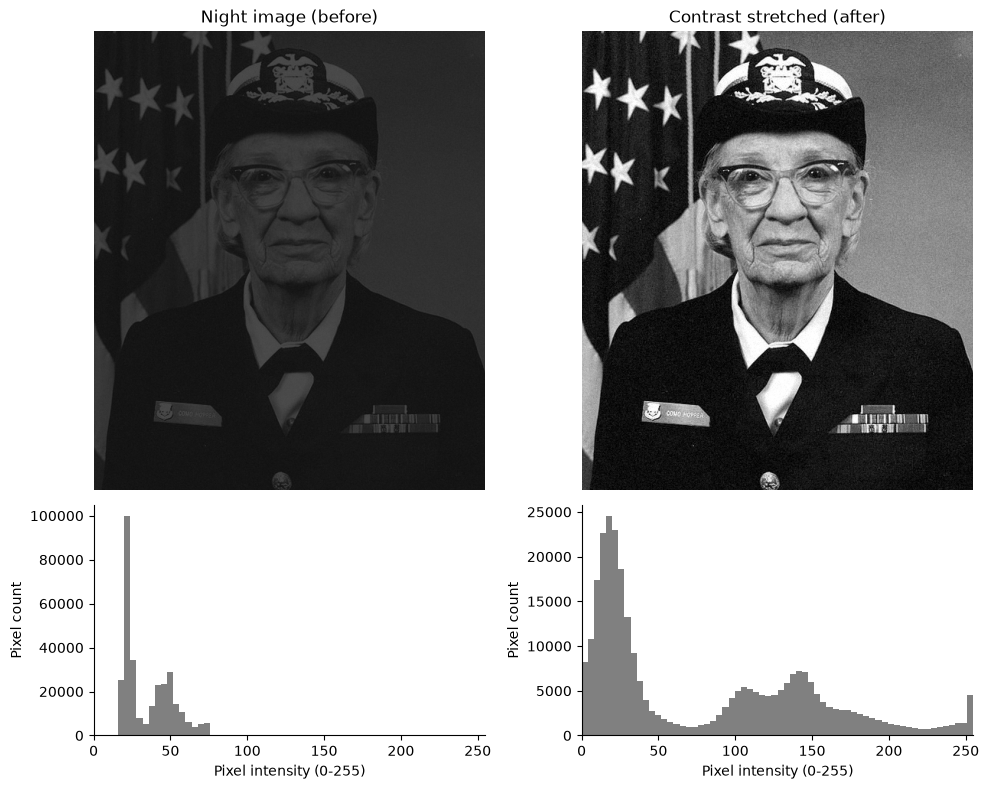

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

q1, q99 = np.percentile(stretched, [1, 99])
c_after = michelson(q99, q1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (data, name) in enumerate([(night_still, "Night image (before)"), (stretched, "Contrast stretched (after)")]):
    axes[0, col].imshow(data, cmap="gray", vmin=0, vmax=255)   # fixed 0-255 scale so the dark image looks dark
    axes[0, col].set_title(name); axes[0, col].axis("off")
    axes[1, col].hist(data.ravel(), bins=64, range=(0, 255), color="gray")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("Pixel intensity (0-255)"); axes[1, col].set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The histogram is narrow and squeezed into the dark end, roughly from 15 to 80 out of 255, with two small humps and nothing near white. In the lecture's words it is a low key (under exposed) histogram with low contrast. Stretching spreads those values across the full 0 to 255 range, so the same differences between pixels become big enough for the eye to see. Every pixel keeps its order from darkest to brightest and no new detail was added (the noise gets stretched too). The Michelson contrast rose from 0.609 to 1.000, although 0.609 looks high only because the formula is a ratio and the values are small. A histogram only counts how many pixels have each brightness and says nothing about where they are. A different picture, or the same picture with its pixels shuffled, can have exactly the same histogram, so the histogram can show that exposure is the problem but can never show what is in the picture.


## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7 s to 78.1 s
Running: 78.6 s to 86.0 s
Loud sound at 75.0 s | Lighting jump at 100.0 s


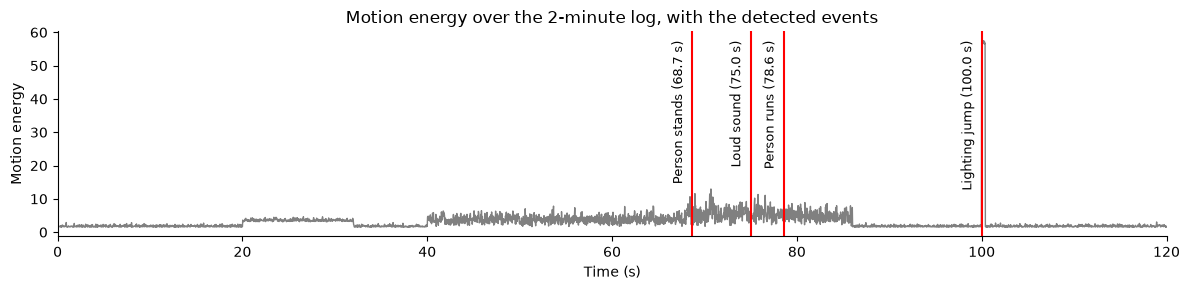

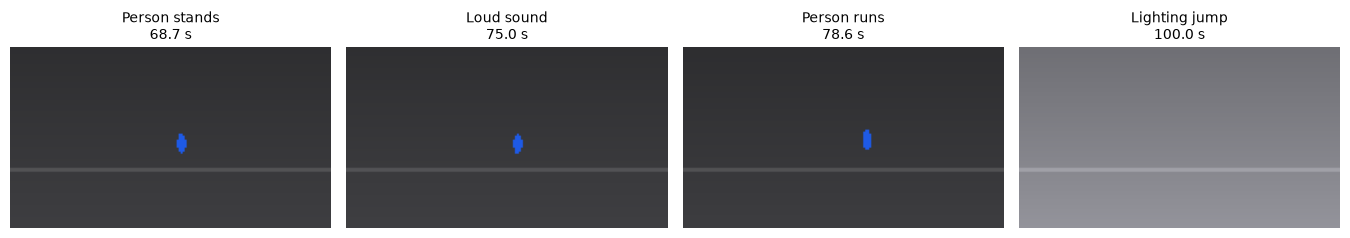

In [4]:
# TODO 1: person speed (px/s)
dx = cctv["person_x"].diff(FPS)          # change over 30 frames = 1 second
dy = cctv["person_y"].diff(FPS)
speed = np.hypot(dx, dy)                 # pixels moved in 1 s = px/s

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = cctv["time_s"][speed < 3]
running = cctv["time_s"][speed > 25]
for name, times in [("Standing", standing), ("Running", running)]:
    print(f"{name}: {times.iloc[0]:.1f} s to {times.iloc[-1]:.1f} s")

# TODO 3: event frame indices
audio_event_idx = int(np.flatnonzero(cctv["audio_level_db"].values > -20)[0])
lighting_event_idx = int(np.flatnonzero(cctv["mean_brightness"].diff().abs().values > 40)[0])
print(f"Loud sound at {cctv.time_s[audio_event_idx]:.1f} s | Lighting jump at {cctv.time_s[lighting_event_idx]:.1f} s")

events = {
    "Person stands": int(standing.index[0]),
    "Loud sound": audio_event_idx,
    "Person runs": int(running.index[0]),
    "Lighting jump": lighting_event_idx,
}

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv["time_s"], cctv["motion_energy"], color="gray", lw=1)
top = cctv["motion_energy"].max()
for name, i in events.items():
    t = cctv.time_s[i]
    ax.axvline(t, color="red", lw=1.5)
    ax.text(t - 0.8, top, f"{name} ({t:.1f} s)", rotation=90, va="top", ha="right", fontsize=9)
ax.set_xlim(0, 120)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("Motion energy over the 2-minute log, with the detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3.4 * len(events), 2.8))
for ax_k, (name, i) in zip(axes, events.items()):
    ax_k.imshow(render_frame(cctv.iloc[i]))
    ax_k.set_title(f"{name}\n{cctv.time_s[i]:.1f} s", fontsize=10)
    ax_k.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ Uniform keyframes at 0, 20, 40, 60, 80 and 100 s would most likely miss the loud sound at 75.0 s, because it falls between the samples at 60 s and 80 s. They would also miss the moment the person stands still at 68.7 s and the moment the person starts running at 78.6 s. The lighting jump at 100.0 s would only be caught by luck, because it lasts about a second and 100 happens to be a multiple of 20. Sparse events are short, so a fixed time step can skip them completely. The approach I used is content-based keyframe selection, where frames are chosen because something changed (speed, sound level, brightness) and not because a timer reached a fixed step.


## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

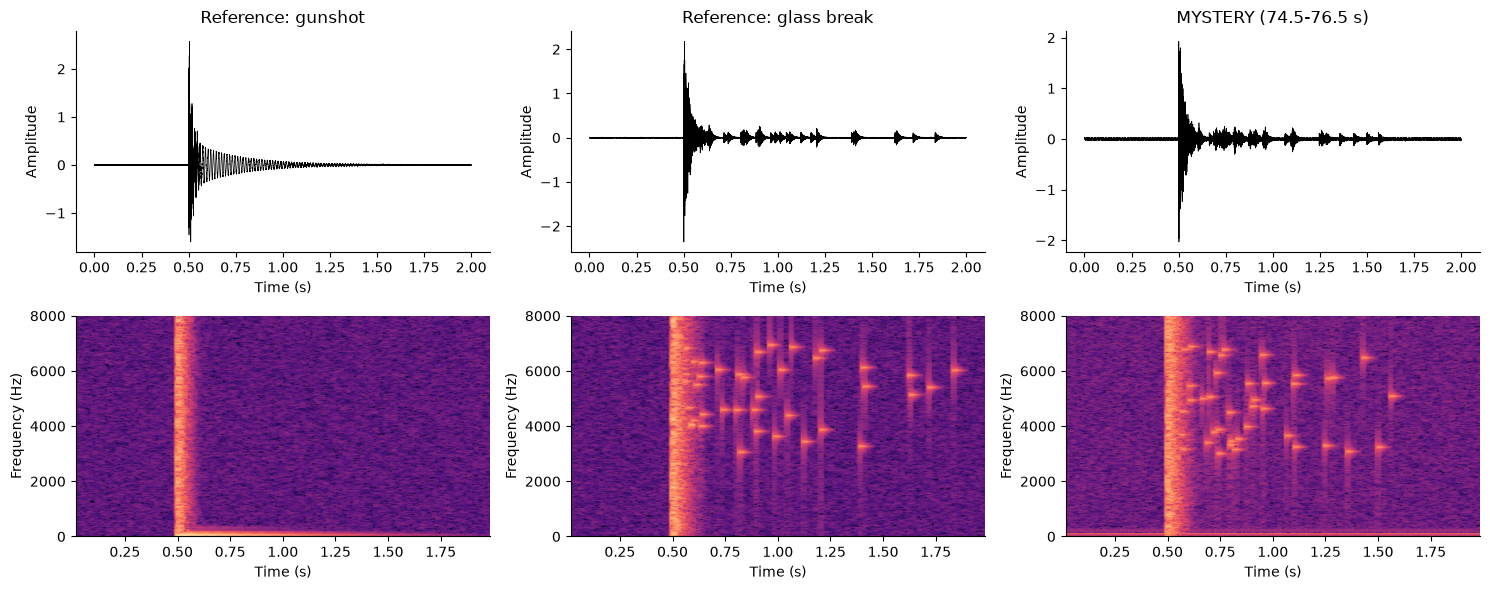

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.99, 'MYSTERY (74.5-76.5 s)': 0.879}
Verdict: the sound at about 75 s is BREAKING GLASS, with 88% of its energy above 3 kHz after the impact (gunshot reference 0%, glass reference 99%).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
specs = {name: signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384) for name, x in clips.items()}
vmax = max(10 * np.log10(S + 1e-12).max() for _, _, S in specs.values())   # same color scale for all three
for col, (name, x) in enumerate(clips.items()):
    axes[0, col].plot(np.arange(x.size) / FS, x, lw=0.5, color="black")
    axes[0, col].set_title(name); axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")
    f, tt, S = specs[name]
    axes[1, col].pcolormesh(tt, f, 10 * np.log10(S + 1e-12), shading="gouraud", cmap="magma", vmin=vmax - 90, vmax=vmax)
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    seg = x[int(0.7 * FS):int(1.7 * FS)]
    power = np.abs(np.fft.rfft(seg)) ** 2
    freqs = np.fft.rfftfreq(seg.size, 1 / FS)
    hf_fraction[name] = round(float(power[freqs > 3000].sum() / power.sum()), 3)

print(hf_fraction)
# TODO 4: verdict
midpoint = (hf_fraction["Reference: gunshot"] + hf_fraction["Reference: glass break"]) / 2
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
verdict = "BREAKING GLASS" if m > midpoint else "a GUNSHOT"
print(f"Verdict: the sound at about 75 s is {verdict}, with {m:.0%} of its energy above 3 kHz after the impact "
      f"(gunshot reference {hf_fraction['Reference: gunshot']:.0%}, glass reference {hf_fraction['Reference: glass break']:.0%}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No. In all three waveforms there is a sharp spike at 0.5 s followed by a fading tail, and they look very alike, so I could not tell the gunshot from the glass break with confidence. The spectrogram adds frequency on the vertical axis, next to time on the horizontal axis, with the magnitude (how loud each frequency is) shown as color brightness. These are the three dimensions: time, frequency and magnitude. The pattern that decided my verdict was the scattered high frequency specks after the impact. The gunshot shows a vertical stripe at the impact and then only a low band near the bottom, while the glass break and the mystery sound both show many small specks between about 3 and 7 kHz after the impact. The thin line at the bottom of the mystery spectrogram is the 120 Hz background hum, not a gunshot boom. The numbers agree: 88% of the mystery sound's energy is above 3 kHz, against 99% for glass and 0% for the gunshot. The sound is breaking glass.


## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

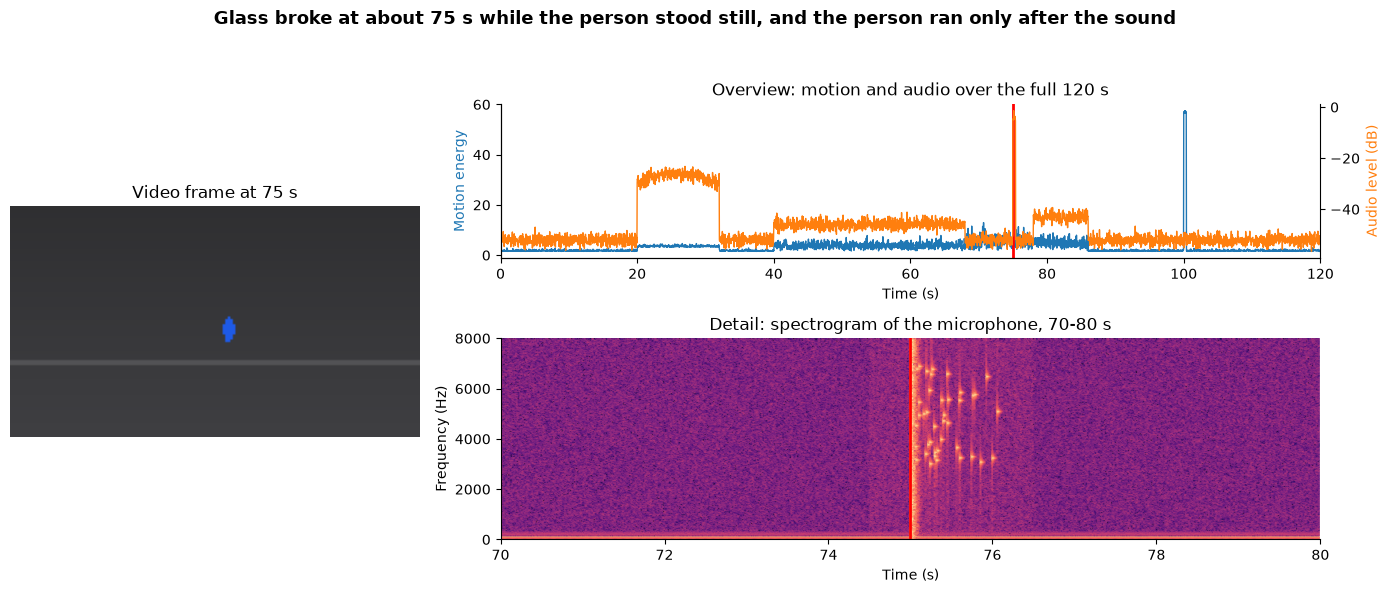

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
# 1. video frame at t_sel (left)
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[int(round(t_sel * FPS))]))
ax_frame.set_title(f"Video frame at {t_sel:.0f} s"); ax_frame.axis("off")

# 2. full 120 s motion + audio timeline with red marker (top right)
ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv["time_s"], cctv["motion_energy"], color="tab:blue", lw=1)
ax_tl.set_ylabel("Motion energy", color="tab:blue")
ax_au = ax_tl.twinx()
ax_au.spines["right"].set_visible(True)
ax_au.plot(cctv["time_s"], cctv["audio_level_db"], color="tab:orange", lw=1)
ax_au.set_ylabel("Audio level (dB)", color="tab:orange")
ax_tl.axvline(t_sel, color="red", lw=2)
ax_tl.set_xlim(0, 120); ax_tl.set_xlabel("Time (s)")
ax_tl.set_title("Overview: motion and audio over the full 120 s")

# 3. spectrogram of x_audio (70-80 s) with the same marker (bottom right)
ax_sp = fig.add_subplot(gs[1, 1])
f, tt, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_sp.pcolormesh(tt + 70, f, 10 * np.log10(S + 1e-12), shading="gouraud", cmap="magma")
ax_sp.set_ylim(0, 8000); ax_sp.set_xlim(70, 80)
ax_sp.axvline(t_sel, color="red", lw=2)
ax_sp.set_xlabel("Time (s)"); ax_sp.set_ylabel("Frequency (Hz)")
ax_sp.set_title("Detail: spectrogram of the microphone, 70-80 s")

# 4. conclusion-style title
fig.suptitle("Glass broke at about 75 s while the person stood still, and the person ran only after the sound",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ The briefing would link the sound to the wrong moment. With the audio shifted by +2 s, the bang would show up at 77 s instead of 75 s, so the person would seem to start running only about 1.6 s after the sound instead of 3.6 s, and the story about how the person reacted would be wrong. The frame at the red marker would also not match the sound that the audio panels show there. The mistake would be visible in the top right timeline and in the spectrogram, because the loud burst would sit two seconds away from the red marker instead of exactly on it.


## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ At about 75 s a loud impact was recorded in Lot B and it was breaking glass, not a gunshot: the person stood still from about 69 s to 78 s, then ran from about 79 s to 86 s, and the lights jumped at 100 s. I would put the timeline first, because the idea of structure, pattern, change, event and meaning starts with an overview of when something changed, and content-based keyframes let you see every moment that matters in two minutes of footage without watching it. The spectrogram then settles the question, because scattered high frequency specks after the impact (88% of the energy above 3 kHz, against 0% for the gunshot reference) mean glass, so the glass response applies. Storing everything in full HD for 400 cameras would need about 5,866 TB per day, so I recommend recording continuously at 640 x 360 and 10 fps (about 217 TB per day) and keeping full 1080p at 30 fps only around triggered events. The one thing this policy must not sacrifice is the full resolution picture of the person during those event windows, because faces and clothing cannot be recovered once the detail is thrown away.
